# Entity matching: parameter estimation walkthrough

This notebook estimates Fellegi-Sunter parameters **without labels**, then
uses the synthetic ground truth to check every estimate. The checks are the
point: each step has a common default that looks fine and is quietly wrong,
and the labels show by how much.

| Step | Estimates | Without labels via | Default that fails |
|---|---|---|---|
| 4 | u: P(level \| non-match) | entity-vs-entity pairs | random query-vs-entity pairs |
| 5 | m: P(level \| match) | EM per blocking round, u fixed | one EM over all candidates |
| 6 | value-specific u | (count − 1) / N with floor | count / N |
| 8 | match probability | query-level posterior | pairwise posterior, prior 1/N |

Data: `generate_data.py` (50,000 entities, 20,000 queries, 15% of queries
unknown). Code: `matching.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import matching as mt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
ATTRS = [c.attr for c in mt.COMPARISONS]

E = pd.read_csv("data/entities.csv")
Q = pd.read_csv("data/queries.csv")
T = pd.read_csv("data/truth.csv")
N, NQ = E.entity_id.nunique(), Q.query_id.nunique()
print(f"{N:,} entities / {len(E):,} rows; {NQ:,} queries / {len(Q):,} rows")
print(f"queries with a true match in the table: {T.entity_id.notna().mean():.1%}")

50,000 entities / 211,551 rows; 20,000 queries / 59,020 rows
queries with a true match in the table: 85.0%


## 1. What the data looks like

Attributes per entity range from 1 to 10. Coverage is uneven: every entity
has a name, but only ~40% have a tax id. That unevenness is why the null
level must contribute 0 rather than count as disagreement.

In [2]:
per = E.groupby("entity_id").size()
print("attributes per entity:", per.describe()[["min", "50%", "max"]].to_dict())
cov = E.groupby("attr_type").entity_id.nunique().div(N).rename("entity_coverage")
qcov = Q.groupby("attr_type").query_id.nunique().div(NQ).rename("query_coverage")
shared = (E.groupby(["attr_type", "value"]).entity_id.nunique()
          .groupby("attr_type").agg(max_entities_per_value="max"))
pd.concat([cov, qcov, shared], axis=1).round(3)

attributes per entity: {'min': 1.0, '50%': 4.0, 'max': 10.0}


,entity_coverage,query_coverage,max_entities_per_value
attr_type,,,
address,0.901,0.704,242
email,0.424,0.262,2
name,1.000,0.923,4
phone,0.769,0.606,106
tax_id,0.399,0.202,1
website,0.421,0.213,3


The `max_entities_per_value` column shows the shared-value problem: one
address is used by ~240 entities (a registered-agent office) and one phone
by ~100 (an answering service). Agreeing on those is close to worthless,
and a single weight per attribute can't express that.

## 2. Normalize

Every downstream number depends on this step. Suite numbers are stripped
from addresses, so all tenants of a building share one normalized address.
This is intentional, and it is why step 6 is needed.

In [3]:
e = mt.normalize(E, "entity_id")
q = mt.normalize(Q, "query_id")
tf = mt.value_tf(e)
Q.head(6).assign(norm=q.head(6).norm.values)

,query_id,attr_type,value,norm
0,Q000000,name,Ostcorbri Marketing Company,ostcorbri marketing
1,Q000000,address,"71 Mowexmar Ave, Chicago, IL 60606",71 mowexmar ave chicago il 60606
2,Q000000,phone,(801) 852-9988,8018529988
3,Q000000,email,kpatel@ostcorbrimarketing.com,kpatel@ostcorbrimarketing.com
4,Q000001,name,Brihel Sola rCorp,brihel sola rcorp
5,Q000001,phone,6089436325,6089436325


## 3. Blocking and comparison vectors

Candidates are pairs that share an exact normalized value on any
attribute, or a rare name token (held by ≤ 30 entities). Blocking recall is
a hard ceiling: a true match that never becomes a candidate can't be found.

In [4]:
cand = pd.concat([mt.block_exact(q, e, ATTRS), mt.block_name_tokens(q, e)]).drop_duplicates()
truth = T.dropna(subset=["entity_id"]).rename(columns={"query_id": "qid", "entity_id": "eid"})
recall = truth.merge(cand, on=["qid", "eid"]).shape[0] / len(truth)
print(f"candidate pairs: {len(cand):,} ({len(cand) / NQ:.1f} per query)")
print(f"blocking recall: {recall:.1%}")

L = mt.compare(cand, q, e, tf)
L.head()

candidate pairs: 274,180 (13.7 per query)
blocking recall: 97.8%


,qid,eid,name,tf_name,address,tf_address,phone,tf_phone,email,tf_email,website,tf_website,tax_id,tf_tax_id
0,Q000000,E024795,4,0.00002,3,0.00002,2,0.00002,0,NaN,0,NaN,0,NaN
1,Q000002,E001005,4,0.00004,1,NaN,0,NaN,0,NaN,0,NaN,0,NaN
2,Q000002,E008908,4,0.00004,2,NaN,2,0.00002,0,NaN,0,NaN,0,NaN
3,Q000004,E021160,4,0.00002,3,0.00002,0,NaN,0,NaN,0,NaN,0,NaN
4,Q000005,E000216,4,0.00002,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN


Level codes: 0 = null, 1 = disagree, higher = stronger agreement. See
`mt.COMPARISONS` for the labels. The `tf_<attr>` columns hold the
frequency of the agreeing value and are used in step 6.

Labeled reference values come next. In practice you won't have these.
They exist here only to grade the unlabeled estimates.

In [5]:
TL = mt.compare(truth[["qid", "eid"]], q, e, tf)
m_true = mt.level_dist(TL)

rng = np.random.default_rng(0)
RQ = pd.DataFrame({"qid": rng.choice(q.id.unique(), 1_000_000),
                   "eid": rng.choice(e.id.unique(), 1_000_000)}).drop_duplicates()
RQ = mt.compare(RQ, q, e, tf)
is_match = RQ.merge(truth[["qid", "eid"]].assign(hit=1), on=["qid", "eid"], how="left")["hit"].notna().values
u_true = mt.level_dist(RQ[~is_match])
print(f"true matches inside 1M 'random' query-entity pairs: {is_match.sum()}")

true matches inside 1M 'random' query-entity pairs: 21


## 4. Estimate u

u is the easy parameter, since almost every random pair is a non-match.
"Almost" is the catch. The match rate in random pairs is ≈ ρ/N ≈ 1.7e-5,
and u for a discriminating level like *exact name* is the same order of
magnitude. The few true matches in a random sample therefore inflate u
exactly where it matters.

The fix: if the known-entity table is deduplicated, **pairs of distinct
entities are non-matches by construction**. The tradeoff is that entity
values are cleaner than query values, so u for fuzzy levels comes out too
low. Step 7 deals with that.

In [6]:
a_, b_ = rng.choice(e.id.unique(), 2_000_000), rng.choice(e.id.unique(), 2_000_000)
EE = mt.compare(pd.DataFrame({"qid": a_[a_ != b_], "eid": b_[a_ != b_]}).drop_duplicates(), e, e, tf)
u = mt.level_dist(EE)
u_contaminated = mt.level_dist(RQ)

rows = []
for c in mt.COMPARISONS:
    top = c.n_levels - 1
    rows.append({"attr": c.attr, "level": c.labels[top], "u_labeled": u_true[c.attr][top],
                 "u_random_query_pairs": u_contaminated[c.attr][top], "u_entity_pairs": u[c.attr][top]})
pd.DataFrame(rows).set_index("attr").style.format(
    "{:.2e}", subset=["u_labeled", "u_random_query_pairs", "u_entity_pairs"])

,level,u_labeled,u_random_query_pairs,u_entity_pairs
attr,,,,
name,exact,2.17e-06,2.17e-05,2.50e-06
address,exact,8.99e-05,1.04e-04,9.19e-05
phone,agree,6.44e-06,1.72e-05,2.62e-05
email,agree,9.00e-06,5.40e-05,2.78e-06
website,agree,1.12e-05,2.24e-05,8.48e-06
tax_id,agree,1.24e-05,4.98e-05,3.15e-06


Random query pairs overstate u for name (10×), email (6×) and tax id (4×).
The 21 true matches in the sample are the excess. Entity pairs avoid this.
Address is fine either way, because its u is driven by genuinely shared
buildings. For phone, entity pairs *over*state u (entities carry more phones
than a query does), which errs conservative.

There is a second limitation that labels don't fix. For name, email,
website and tax id, distinct entities almost never agree, so every column
here is at or near the pseudo-count floor, 1 / (number of non-null pairs).
Those u values, and therefore the top weights, are set by **sample size**:
twice as many pairs would add about one bit. The query-level posterior in
step 8 limits how much this matters, but it is a real source of
overconfidence when one of these attributes is the only evidence.

## 5. Estimate m with EM

m needs matches, and matches are only common among candidate pairs. Those
pairs were selected for agreeing on something, which breaks the obvious
approach.

### 5a. The naive approach: one EM over all candidates

In [7]:
naive = mt.em(L, u, ATTRS)
print(f"naive EM: lambda = {naive.lam:.3f}, iterations = {naive.n_iter}")
pd.DataFrame({a: {"m_agree_naive": naive.m[a][-1], "m_agree_true": m_true[a][-1]} for a in ATTRS}).T.round(3)

naive EM: lambda = 0.688, iterations = 152


,m_agree_naive,m_agree_true
name,0.086,0.904
address,0.424,0.852
phone,0.116,0.730
email,0.091,0.830
website,0.138,1.000
tax_id,0.101,0.984


This is badly wrong. Every candidate agrees on its blocking value, and u
(from random pairs) says such agreement is rare among non-matches. So EM
labels nearly all candidates as matches. The non-matches pulled in through
a shared building address then become "matches" that disagree on
everything else, and m for agreement collapses.

### 5b. The fix: one EM round per blocking rule, excluding the blocked attribute

Within the pairs blocked on exact name, name carries no information (every
pair agrees), so it is left out and the others are estimated. Then the same
is done for pairs blocked on phone. Each attribute is estimated in at least
one round where it was not used for selection. u is held fixed throughout.
This is the approach Splink uses.

In [8]:
pairs_name = L.merge(mt.block_exact(q, e, ["name"]), on=["qid", "eid"])
pairs_phone = L.merge(mt.block_exact(q, e, ["phone"]), on=["qid", "eid"])
r_name = mt.em(pairs_name, u, [a for a in ATTRS if a != "name"])
r_phone = mt.em(pairs_phone, u, [a for a in ATTRS if a != "phone"])
print(f"round blocked on name : {len(pairs_name):,} pairs, lambda {r_name.lam:.3f}, {r_name.n_iter} iters")
print(f"round blocked on phone: {len(pairs_phone):,} pairs, lambda {r_phone.lam:.3f}, {r_phone.n_iter} iters")

m = {}
for a in ATTRS:
    ests = [r.m[a] for r in (r_name, r_phone) if a in r.m]
    m[a] = np.mean(ests, axis=0)

cmp_rows = []
for c in mt.COMPARISONS:
    for lv in range(1, c.n_levels):
        cmp_rows.append({"attr": c.attr, "level": c.labels[lv], "m_true": m_true[c.attr][lv],
                         "em_name_round": r_name.m.get(c.attr, [np.nan] * c.n_levels)[lv],
                         "em_phone_round": r_phone.m.get(c.attr, [np.nan] * c.n_levels)[lv],
                         "em_combined": m[c.attr][lv], "naive": naive.m[c.attr][lv]})
mcmp = pd.DataFrame(cmp_rows)
mcmp.round(3)

round blocked on name : 15,785 pairs, lambda 0.900, 26 iters
round blocked on phone: 10,601 pairs, lambda 0.546, 9 iters


,attr,level,m_true,em_name_round,em_phone_round,em_combined,naive
0,name,none,0.020,NaN,0.020,0.020,0.756
1,name,jw>=0.85,0.007,NaN,0.007,0.007,0.150
2,name,jw>=0.94,0.070,NaN,0.070,0.070,0.007
3,name,exact,0.904,NaN,0.903,0.903,0.086
4,address,disagree,0.104,0.099,0.026,0.063,0.573
5,address,lev>=0.90,0.044,0.045,0.047,0.046,0.003
6,address,exact,0.852,0.856,0.927,0.891,0.424
7,phone,disagree,0.270,0.263,NaN,0.263,0.884
8,phone,agree,0.730,0.737,NaN,0.737,0.116
9,email,disagree,0.170,0.170,0.176,0.173,0.909


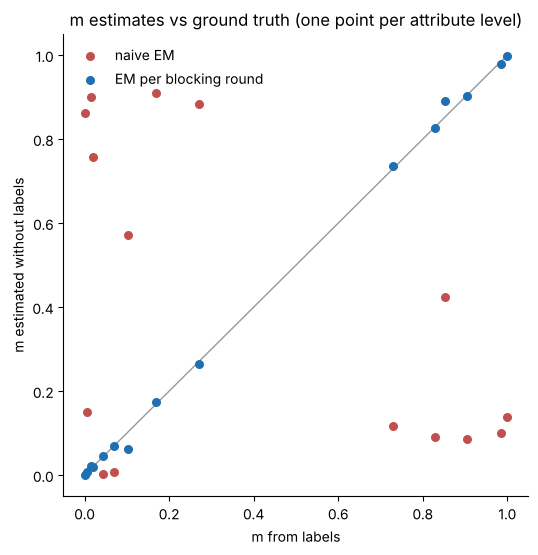

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="#999", lw=1, zorder=0)
ax.scatter(mcmp.m_true, mcmp.naive, label="naive EM", color="#c0504d", s=30)
ax.scatter(mcmp.m_true, mcmp.em_combined, label="EM per blocking round", color="#1f6fb2", s=30)
ax.set_xlabel("m from labels")
ax.set_ylabel("m estimated without labels")
ax.set_title("m estimates vs ground truth (one point per attribute level)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Per-round EM recovers m to within about ±0.01 for most levels. The
exception is informative. In the phone-blocked round, **address**
agreement is inflated (≈0.93 vs 0.85 true). Pairs blocked on a matching
phone are disproportionately entities that haven't moved, and moving
changes address and phone together. This is the conditional-independence
violation from the earlier summary showing up in the estimates themselves.
Averaging across rounds dilutes it, but nothing here removes it.

Also note that m for `website: disagree` is ≈0.001. In this synthetic data
websites essentially never change. Real websites do, and the −10-bit
penalty this produces would be wrong. Read EM output with domain knowledge.

## 6. Value-specific u (term frequency)

The textbook term-frequency adjustment sets u_v = count_v / N. It has two
problems:

- It counts the query's own entity among the holders. For a value held by
  2 entities, one of which is the match, only **1** other holder is a
  coincidence.
- It puts a floor of 1/N on every agreement. For names, distinct entities
  coincide at about 1e-6, which is 20× less than 1/N here.

`mt.score` uses u_v = max((count_v − 1)/N, u_exact) instead. The hub cases:

In [10]:
lw = mt.level_weights(m, u)
examples = []
for attr in ["address", "phone", "name"]:
    t = tf[tf.attr_type == attr].sort_values("tf", ascending=False)
    for label, row in [("most shared", t.iloc[0]), ("held by 2", t[(t.tf * N).round() == 2].iloc[0]),
                       ("unique", t[(t.tf * N).round() == 1].iloc[0])]:
        cnt = round(row.tf * N)
        top = m[attr][-1]
        examples.append({"attr": attr, "value": label, "count": cnt,
                         "w_no_tf": lw[attr][-1],
                         "w_textbook_tf": np.log2(top / row.tf),
                         "w_used": np.log2(top / max((cnt - 1) / N, u[attr][-1]))})
pd.DataFrame(examples).round(2)

,attr,value,count,w_no_tf,w_textbook_tf,w_used
0,address,most shared,242,13.24,7.52,7.53
1,address,held by 2,2,13.24,14.44,13.24
2,address,unique,1,13.24,15.44,13.24
3,phone,most shared,106,14.78,8.44,8.45
4,phone,held by 2,2,14.78,14.17,14.78
5,phone,unique,1,14.78,15.17,14.78
6,name,most shared,4,18.46,13.46,13.88
7,name,held by 2,2,18.46,14.46,15.46
8,name,unique,1,18.46,15.46,18.46


Agreeing on the registered-agent address is worth ~7.5 bits instead of
~13. Agreeing on a unique name keeps its full ~18.5 bits instead of the
~15.5 the textbook formula gives. A name shared by two entities drops to
~15.5, and the query-level posterior then splits the probability between
them.

The `(count − 1)` correction assumes the query's entity is one of the
holders. That is optimistic for unknown queries, and the `u_exact` floor is
what keeps it from becoming overconfident.

## 7. Weights

In [11]:
wt = mt.weight_table(m, u)
wt["weight_used"] = np.concatenate([lw[c.attr] for c in mt.COMPARISONS])
wt[wt.level > 0].round(3)

,attr,level,label,m,u,weight,weight_used
1,name,1,none,0.020,0.999,-5.657,-5.657
2,name,2,jw>=0.85,0.007,0.001,3.787,3.787
3,name,3,jw>=0.94,0.070,0.000,12.453,12.453
4,name,4,exact,0.903,0.000,18.462,18.462
6,address,1,disagree,0.063,1.000,-3.995,-3.995
7,address,2,lev>=0.90,0.046,0.000,16.191,13.243
8,address,3,exact,0.891,0.000,13.243,13.243
10,phone,1,disagree,0.263,1.000,-1.925,-1.925
11,phone,2,agree,0.737,0.000,14.778,14.778
13,email,1,disagree,0.173,1.000,-2.528,-2.528


Two things to check in any weight table:

1. **Monotonicity.** `address lev>=0.90` has a raw weight above `exact`.
   Entity-vs-entity pairs contain no typos, so the fuzzy-level u is
   underestimated. `weight_used` caps each fuzzy level at the level above
   it.
2. **Disagreement penalties track volatility.** Phone (−1.9) and email
   (−2.5) are mild. Tax id (−5.5) and name (−5.7) are stiff. These come out
   of the data, not hand-tuning, which is the main reason to estimate rather
   than set them.

## 8. From score to probability

A pairwise posterior uses prior odds of about ρ/N, roughly −16 bits here.
It treats the other N−1 entities as uninformative, when in fact they mostly
*disagree* with the query. That makes it underconfident, and two tied
candidates can both look certain.

`mt.query_posterior` instead normalizes over all N entities. Candidates
contribute their Bayes factor, and non-candidates contribute an
approximate background factor. It also estimates ρ (the share of queries
with a match) by EM.

In [12]:
S = mt.score(L, m, u, n_entities=N)

prior = mt.estimate_prior(S, NQ * N)
S["p_pairwise"] = mt.to_prob(S.score.values, prior)

P, rho = mt.query_posterior(S, q, e, m, u)
print(f"rho (share of queries with a match): estimated {rho:.3f}, true {T.entity_id.notna().mean():.3f}")
print("the gap is mostly the ~2% of true matches lost at blocking")


def top_per_query(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """
    Best candidate per query by ``col``, joined to truth.

    :param df: scored pairs
    :param col: probability column
    :return: one row per query (including queries with no candidates)
    """
    t = df.sort_values(col, ascending=False).drop_duplicates("qid")[["qid", "eid", col]]
    out = T.rename(columns={"query_id": "qid", "entity_id": "true_eid"}).merge(t, on="qid", how="left")
    out[col] = out[col].fillna(0.0)
    out["correct"] = out.eid == out.true_eid
    return out


bins = [-0.001, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]
cal = {}
for col in ["p_pairwise", "p"]:
    d = top_per_query(P, col)
    cal[col] = d.groupby(pd.cut(d[col], bins), observed=True).agg(
        n=("correct", "size"), predicted=(col, "mean"), observed=("correct", "mean"))
pd.concat(cal, axis=1).round(3)

rho (share of queries with a match): estimated 0.802, true 0.850
the gap is mostly the ~2% of true matches lost at blocking


p_pairwise                         p                   
                       n predicted observed      n predicted observed
(-0.001, 0.1]       3917     0.011    0.170   3333     0.004    0.052
(0.1, 0.3]           885     0.214    0.853    259     0.183    0.722
(0.3, 0.5]           223     0.419    0.717    853     0.358    0.849
(0.5, 0.7]           491     0.596    0.921    524     0.629    0.840
(0.7, 0.9]          1846     0.845    0.974    588     0.863    0.906
(0.9, 0.95]            3     0.939    1.000     47     0.920    0.936
(0.95, 0.99]          60     0.982    0.917   1821     0.965    0.976
(0.99, 1.0]        12575     1.000    0.998  12575     1.000    0.999

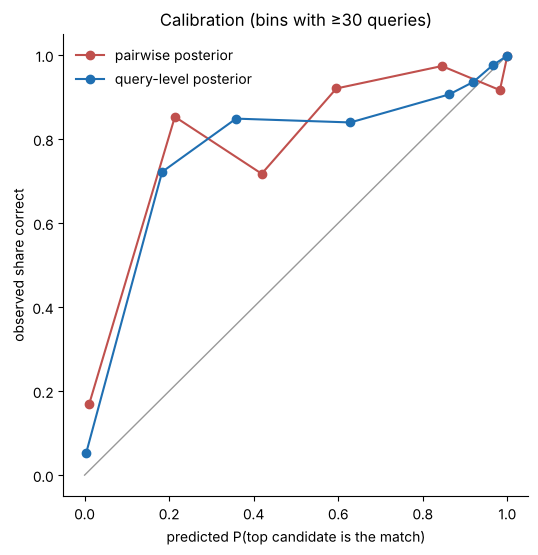

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="#999", lw=1, zorder=0)
for col, label, color in [("p_pairwise", "pairwise posterior", "#c0504d"), ("p", "query-level posterior", "#1f6fb2")]:
    c = cal[col][cal[col].n >= 30]
    ax.plot(c.predicted, c.observed, marker="o", label=label, color=color)
ax.set_xlabel("predicted P(top candidate is the match)")
ax.set_ylabel("observed share correct")
ax.set_title("Calibration (bins with ≥30 queries)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Both are underconfident in the middle, and neither is calibrated there.
The difference is in where queries land. The pairwise version leaves
~3,400 queries in the 0.1–0.9 band. The query-level version leaves ~2,200,
and moves the rest into ≥ 0.95, where they are 97.6% correct. That shift
raises the auto-accept rate at 0.95 from 63% to 72%, for a 0.2-point drop
in precision (99.8% → 99.6%).

The query-level version is still **underconfident in 0.1–0.7** (predicted
0.18 → observed 0.72; 0.36 → 0.85).
Those queries are mostly "exact name, address disagrees" (moves and
franchises) and "address only" (shared buildings). Residual correlation
between attributes, plus the crude background factor, account for the gap.
If the band matters to you, a small labeled sample plus isotonic regression
on `p` fixes it more cheaply than refining the model.

## 9. Decisions

In [14]:
D = mt.decide(P, accept_p=0.95, review_p=0.5)
D = T.rename(columns={"query_id": "qid", "entity_id": "true_eid"}).merge(D, on="qid", how="left")
D["decision"] = D.decision.fillna("no_match")
D["outcome"] = np.select(
    [D.true_eid.isna() & (D.decision == "no_match"), D.true_eid.isna(),
     D.eid == D.true_eid, D.decision == "no_match"],
    ["correct reject", "unknown matched", "right entity", "missed"], "wrong entity")
print(pd.crosstab(D.decision, D.outcome, margins=True))
acc = D[D.decision == "accept"]
print(f"\nauto-accept rate {len(acc) / len(D):.1%}, precision {(acc.eid == acc.true_eid).mean():.2%}")
print(f"review rate {(D.decision == 'review').mean():.1%}")

outcome   correct reject  missed  right entity  unknown matched  wrong entity    All
decision                                                                            
accept                 0       0         14334               48            14  14396
no_match            2865     510          1070                0             0   4445
review                 0       0          1017               97            45   1159
All                 2865     510         16421              145            59  20000

auto-accept rate 72.0%, precision 99.57%
review rate 5.8%


Threshold sweep, to choose the auto-accept cutoff from a precision target
rather than by feel:

In [15]:
d = top_per_query(P, "p")
sweep = [{"threshold": t, "auto_accept_rate": (d.p >= t).mean(), "precision": d[d.p >= t].correct.mean()}
         for t in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]]
pd.DataFrame(sweep).round(4)

,threshold,auto_accept_rate,precision
0,0.500,0.7778,0.9869
1,0.800,0.7484,0.9927
2,0.900,0.7222,0.9955
3,0.950,0.7198,0.9957
4,0.990,0.6288,0.9986
5,0.999,0.6246,0.9986


### Where it fails

In [16]:
seg = D.assign(segment=np.select([D.true_eid.isna(), D.moved, D.rebranded, D.contaminated],
                                 ["unknown entity", "moved", "rebranded", "contaminated phone"], "other known"))
seg["accepted_wrong"] = (seg.decision == "accept") & seg.outcome.isin(["wrong entity", "unknown matched"])
seg.groupby("segment").agg(n=("qid", "size"),
                           accepted=("decision", lambda s: (s == "accept").mean()),
                           review=("decision", lambda s: (s == "review").mean()),
                           accepted_wrong=("accepted_wrong", "mean")).round(3)

,n,accepted,review,accepted_wrong
segment,,,,
contaminated phone,189,0.767,0.153,0.000
moved,1731,0.432,0.266,0.001
other known,14769,0.903,0.038,0.001
rebranded,301,0.395,0.040,0.003
unknown entity,3010,0.016,0.032,0.016


- **Rebranded:** the name changed and the old one is in the table. Without
  a second attribute these are unrecoverable, and they should end up as
  `no_match`, not as a wrong accept.
- **Moved:** address and phone disagree together. These lean on name, and
  they are much of the review queue.
- **Unknown entities:** 1.6% are auto-accepted, which is 48 of the 62
  wrong accepts overall. These are same-name or same-building hard
  negatives. The dominant error is failing to say "not in the table," not
  choosing the wrong candidate. If false accepts are costly, spend labeling
  effort there.

## Takeaways

1. **Estimate u from pairs you know are non-matches** (distinct entities
   in a deduplicated table), not from random query pairs.
2. **Never run EM on a blocked candidate set with the blocking attribute
   in the model.** Run one round per blocking rule and leave that rule's
   attributes out.
3. **Term frequency needs the count − 1 correction and a floor**, or
   unique values get under-weighted and shared ones over-weighted.
4. **Normalize probabilities per query.** A pairwise posterior is
   underconfident and can't represent a tie between candidates.
5. **Check the model against even a few hundred labels.** Every
   failure above is invisible without them, and the independence
   assumption (move → address and phone change together) shows up in
   both m and calibration.

**Applying this to your data:** `normalize` expects `(id, attr_type,
value)`. Edit `NORMALIZERS` and `COMPARISONS` for your attribute types,
and pick blocking rules for the EM rounds that each leave out a different
attribute.